In [65]:
import math

def euclidean_distance(point_1, point_2):
    # res = 0
    # for i in range(len(point_1)):
    #     res += (point_1[i] - point_2[i]) ** 2
        
    res = sum((point_1[i] - point_2[i]) ** 2 for i in range(len(point_1)))
    return math.sqrt(res)

point_1 = (1, 2, 3)
point_2 = (4, 5, 6)

print(euclidean_distance(point_1, point_2))

5.196152422706632


In [66]:
def manhattan_distance(point_1, point_2):
    res = sum(abs(point_1[i] - point_2[i]) for i in range(len(point_1)))
    
    return res
    
point_1 = (1, 2, 3)
point_2 = (4, 5, 6)

print(manhattan_distance(point_1, point_2))

9


In [67]:
import numpy as np

def cosine_similarity(a, b):
    dot_product = np.dot(a, b)
    norm_a = np.linalg.norm(a)
    norm_b = np.linalg.norm(b)
    
    return dot_product / (norm_a * norm_b)

p_1 = np.array([1, 1, 0, 0])
p_2 = np.array([0, 1, 1, 0])
p_3 = np.array([0, 0, 1, 1])
p_4 = np.array([1, 1, 1, 1])
p_5 = np.array([1, 1, 0, 0])

print(cosine_similarity(p_1, p_2))  # 0.5
print(cosine_similarity(p_1, p_3))  # 0
print(cosine_similarity(p_1, p_4))  # 0.7
print(cosine_similarity(p_1, p_5))  # 1

0.4999999999999999
0.0
0.7071067811865475
0.9999999999999998


In [68]:
import pandas as pd
from pathlib import Path

dataset_path = Path(r"C:\Users\VarunKarmikanda\msis\sem1\aml\practice\dataset\mall.csv")
dataset = pd.read_csv(dataset_path)

# dataset.head()

X = dataset.iloc[:, [3, 4]].values
X

array([[ 15,  39],
       [ 15,  81],
       [ 16,   6],
       [ 16,  77],
       [ 17,  40],
       [ 17,  76],
       [ 18,   6],
       [ 18,  94],
       [ 19,   3],
       [ 19,  72],
       [ 19,  14],
       [ 19,  99],
       [ 20,  15],
       [ 20,  77],
       [ 20,  13],
       [ 20,  79],
       [ 21,  35],
       [ 21,  66],
       [ 23,  29],
       [ 23,  98],
       [ 24,  35],
       [ 24,  73],
       [ 25,   5],
       [ 25,  73],
       [ 28,  14],
       [ 28,  82],
       [ 28,  32],
       [ 28,  61],
       [ 29,  31],
       [ 29,  87],
       [ 30,   4],
       [ 30,  73],
       [ 33,   4],
       [ 33,  92],
       [ 33,  14],
       [ 33,  81],
       [ 34,  17],
       [ 34,  73],
       [ 37,  26],
       [ 37,  75],
       [ 38,  35],
       [ 38,  92],
       [ 39,  36],
       [ 39,  61],
       [ 39,  28],
       [ 39,  65],
       [ 40,  55],
       [ 40,  47],
       [ 40,  42],
       [ 40,  42],
       [ 42,  52],
       [ 42,  60],
       [ 43,

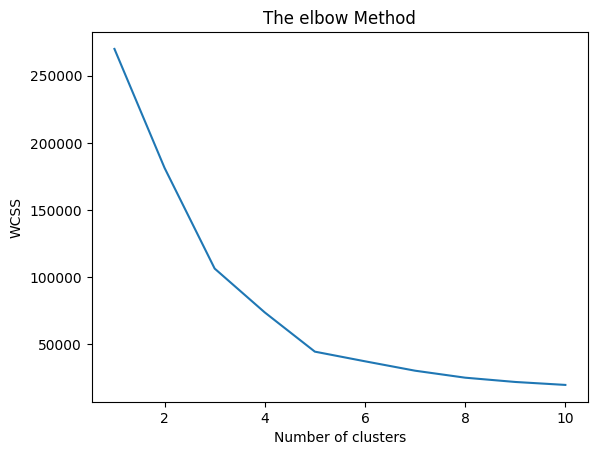

In [69]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init="k-means++", max_iter=300, n_init=10, random_state=0)
    
    kmeans.fit(X)
    
    wcss.append(kmeans.inertia_)
    
    
plt.plot(range(1, 11), wcss)
plt.title("The elbow Method")
plt.xlabel("Number of clusters")
plt.ylabel("WCSS")
plt.show()

In [70]:
kmeans = KMeans(n_clusters=5, init="k-means++", max_iter=300, n_init=10, random_state=0)
y_kmeans = kmeans.fit_predict(X)

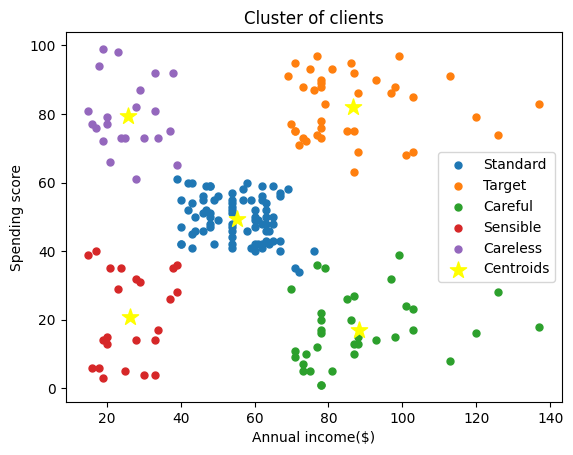

In [89]:
import matplotlib.pyplot as plt

plt.scatter(X[y_kmeans == 0, 0], X[y_kmeans == 0, 1], s=25, label="Standard")
plt.scatter(X[y_kmeans == 1, 0], X[y_kmeans == 1, 1], s=25, label="Target")
plt.scatter(X[y_kmeans == 2, 0], X[y_kmeans == 2, 1], s=25, label="Careful")
plt.scatter(X[y_kmeans == 3, 0], X[y_kmeans == 3, 1], s=25, label="Sensible")
plt.scatter(X[y_kmeans == 4, 0], X[y_kmeans == 4, 1], s=25, label="Careless")

plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=150, c="yellow", label="Centroids", marker="*")

plt.title("Cluster of clients")
plt.xlabel("Annual income($)")
plt.ylabel("Spending score")
plt.legend()

plt.show()

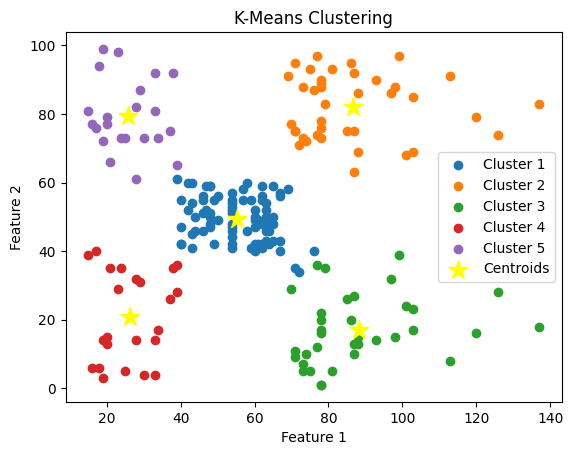

In [72]:
import matplotlib.pyplot as plt

# Plot each cluster
for i in range(5):
    plt.scatter(
        X[y_kmeans == i, 0],
        X[y_kmeans == i, 1],
        label=f'Cluster {i+1}'
    )

# Plot centroids
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    s=200,
    c='yellow',
    marker='*',
    label='Centroids'
)

plt.title("K-Means Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()